In [83]:
# インポート
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [85]:
# Load text files from data directory
data_dir = Path('data')
text_files = sorted(data_dir.glob('*.txt'))

# Create a dictionary to store text data
texts = {}
for file_path in text_files:
    file_name = file_path.stem
    with open(file_path, 'r', encoding='utf-8') as f:
        content = f.read().strip()
    # Split by spaces to get words
    words = content.split()
    texts[file_name] = {
        'words': words,
        'raw_text': content,
        'word_count': len(words)
    }
    print(f"Loaded {file_name}: {len(words)} words")

print(f"\nTotal files loaded: {len(texts)}")
print(f"Available datasets: {list(texts.keys())}")

Loaded みんなで作る党_参: 2455 words
Loaded れいわ_衆: 7336 words
Loaded チームみらい_衆: 21712 words
Loaded 中道_衆: 2477 words
Loaded 令和新選組_参: 7334 words
Loaded 公明党_参: 2449 words
Loaded 共産党_参: 4965 words
Loaded 参政党_参: 2410 words
Loaded 参政党_衆: 19454 words
Loaded 国民民主_衆: 9549 words
Loaded 国民民主党_参: 2413 words
Loaded 社民党_参: 1092 words
Loaded 立憲民主党_参: 2606 words
Loaded 自民党_参: 3120 words
Loaded 自民党_衆: 7579 words

Total files loaded: 15
Available datasets: ['みんなで作る党_参', 'れいわ_衆', 'チームみらい_衆', '中道_衆', '令和新選組_参', '公明党_参', '共産党_参', '参政党_参', '参政党_衆', '国民民主_衆', '国民民主党_参', '社民党_参', '立憲民主党_参', '自民党_参', '自民党_衆']


In [86]:
texts['自民党_衆']

{'words': ['検索',
  '政権',
  '公約',
  '列島',
  '強く',
  '豊か',
  '51',
  '自由民主党',
  '衆院',
  'メニュー',
  '閉じる',
  '公認',
  '候補',
  '探す',
  '比例',
  '代表',
  '探す',
  '演説',
  '自民党',
  '公約',
  '動画',
  '参加',
  'しよ',
  '投票',
  '方法',
  'ウィンドウ',
  'リンク',
  '出演',
  'ウィンドウ',
  'リンク',
  '自民党',
  '公式',
  'アカウント',
  'ウィンドウ',
  'リンク',
  'ウィンドウ',
  'リンク',
  'Line',
  'ウィンドウ',
  'リンク',
  'youtube',
  'ウィンドウ',
  'リンク',
  'Instagram',
  'ウィンドウ',
  'リンク',
  'TikTok',
  'ウィンドウ',
  'リンク',
  'ウィンドウ',
  'リンク',
  '自民党',
  'ホームページ',
  'ウィンドウ',
  'リンク',
  '候補',
  '探す',
  '政権',
  '公約',
  '公式',
  'ウィンドウ',
  'リンク',
  'ウィンドウ',
  'リンク',
  'Line',
  'ウィンドウ',
  'リンク',
  'youtube',
  'ウィンドウ',
  'リンク',
  'Instagram',
  'ウィンドウ',
  'リンク',
  'TikTok',
  'ウィンドウ',
  'リンク',
  '閉じる',
  '検索',
  '本文',
  '検索',
  '絞り込み',
  '検索',
  '若者',
  'シニア',
  '地方',
  'トピック',
  '選択',
  'カテゴリ',
  '強い',
  '笑顔',
  'あふれる',
  '暮らし',
  '地方',
  'エンジン',
  'わが国',
  '守る',
  '責任',
  '秩序',
  '担う',
  '安心',
  '次世代',
  '責任',
  '時代',
  'ふさわしい',
  '新しい',
  'たち',
  '選択',


In [87]:
# Compare SSDSE/data and SSDSE/04_28/data - Organized by party and chamber
from pathlib import Path
from collections import defaultdict

# Initialize data structures
old_data_dir = Path('../data')
new_data_dir = Path('data')

# Structure: {chamber: {party: {old_words, new_words, diff_info}}}
comparison_by_party = defaultdict(lambda: defaultdict(dict))

# Load old data from SSDSE/data (organized by chamber subdirectories)
old_data_by_party = {}
for chamber_dir in old_data_dir.glob('*'):
    if chamber_dir.is_dir() and chamber_dir.name in ['衆議院', '参議院']:
        chamber_name = chamber_dir.name
        suffix = '_衆' if chamber_name == '衆議院' else '_参'
        
        for file_path in sorted(chamber_dir.glob('*.txt')):
            party_name = file_path.stem
            key = f"{party_name}{suffix}"
            try:
                with open(file_path, 'r', encoding='utf-8') as f:
                    old_data_by_party[key] = set(f.read().strip().split())
            except Exception as e:
                print(f"Error loading {chamber_dir.name}/{party_name}: {e}")

# Load new data from SSDSE/04_28/data
new_data_by_party = {}
for file_path in sorted(new_data_dir.glob('*.txt')):
    key = file_path.stem
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            new_data_by_party[key] = set(f.read().strip().split())
    except Exception as e:
        print(f"Error loading {key}: {e}")

# Compare and organize by chamber and party
print("="*80)
print("テキストファイルの差分比較 (SSDSE/data → SSDSE/04_28/data)")
print("="*80)

for party_key in sorted(new_data_by_party.keys()):
    # Determine chamber
    chamber = '衆議院' if '衆' in party_key else '参議院'
    party_name = party_key.replace('_衆', '').replace('_参', '')
    
    new_words = new_data_by_party[party_key]
    old_words = old_data_by_party.get(party_key, set())
    
    # Calculate differences
    added = new_words - old_words
    removed = old_words - new_words
    common = new_words & old_words
    
    # Store in comparison structure
    comparison_by_party[chamber][party_name] = {
        'old_words': old_words,
        'new_words': new_words,
        'added': added,
        'removed': removed,
        'common': common,
        'metrics': {
            'old_count': len(old_words),
            'new_count': len(new_words),
            'added_count': len(added),
            'removed_count': len(removed),
            'common_count': len(common)
        }
    }
    
    # Display results
    print(f"\n【{chamber}】{party_name}")
    print(f"  旧データ: {len(old_words):5d} words")
    print(f"  新データ: {len(new_words):5d} words")
    print(f"  追加:    {len(added):5d} words")
    print(f"  削除:    {len(removed):5d} words")
    print(f"  共通:    {len(common):5d} words")

# Summary statistics
print("\n" + "="*80)
print("差分統計サマリー")
print("="*80)

for chamber in ['衆議院', '参議院']:
    parties = comparison_by_party[chamber]
    if parties:
        print(f"\n【{chamber}】: {len(parties)} 政党")
        total_added = sum(len(data['added']) for data in parties.values())
        total_removed = sum(len(data['removed']) for data in parties.values())
        print(f"  合計追加: {total_added} words")
        print(f"  合計削除: {total_removed} words")
        
        for party_name in sorted(parties.keys()):
            data = parties[party_name]
            print(f"    {party_name:15s} | +{data['metrics']['added_count']:4d} -{data['metrics']['removed_count']:4d} | "
                  f"{data['metrics']['old_count']:5d} → {data['metrics']['new_count']:5d}")

print("\n✓ comparison_by_party に政党ごとの差分データが格納されました")

テキストファイルの差分比較 (SSDSE/data → SSDSE/04_28/data)

【参議院】みんなで作る党
  旧データ:   120 words
  新データ:  1228 words
  追加:     1207 words
  削除:       99 words
  共通:       21 words

【衆議院】れいわ
  旧データ:   261 words
  新データ:  2336 words
  追加:     2325 words
  削除:      250 words
  共通:       11 words

【衆議院】チームみらい
  旧データ:   452 words
  新データ:  4194 words
  追加:     4177 words
  削除:      435 words
  共通:       17 words

【衆議院】中道
  旧データ:    37 words
  新データ:  1054 words
  追加:     1050 words
  削除:       33 words
  共通:        4 words

【参議院】令和新選組
  旧データ:   261 words
  新データ:  2335 words
  追加:     2324 words
  削除:      250 words
  共通:       11 words

【参議院】公明党
  旧データ:   117 words
  新データ:  1232 words
  追加:     1213 words
  削除:       98 words
  共通:       19 words

【参議院】共産党
  旧データ:   424 words
  新データ:  1894 words
  追加:     1876 words
  削除:      406 words
  共通:       18 words

【参議院】参政党
  旧データ:   114 words
  新データ:  1193 words
  追加:     1174 words
  削除:       95 words
  共通:       19 words

【衆議院】参政党
  旧データ:   638 words
  新データ:  428

In [88]:
# Load old raw text data from SSDSE/data for better comparison
old_raw_texts = {}
old_data_dir = Path('../data')

for chamber_dir in old_data_dir.glob('*'):
    if chamber_dir.is_dir() and chamber_dir.name in ['衆議院', '参議院']:
        chamber_name = chamber_dir.name
        suffix = '_衆' if chamber_name == '衆議院' else '_参'
        
        for file_path in sorted(chamber_dir.glob('*.txt')):
            party_name = file_path.stem
            key = f"{party_name}{suffix}"
            try:
                with open(file_path, 'r', encoding='utf-8') as f:
                    old_raw_texts[key] = f.read().strip()
            except Exception as e:
                print(f"Error loading {chamber_dir.name}/{party_name}: {e}")

print(f"✓ {len(old_raw_texts)} の旧データを読み込みました")

✓ 19 の旧データを読み込みました


In [89]:
# Display first N characters of old and new data for a specified party
def display_party_comparison(party_name, chars_limit=500):
    """
    指定された政党の旧データと新データの最初の数百文字を表示
    
    Parameters:
    - party_name: 政党名 (例: "自民党")
    - chars_limit: 表示する文字数（デフォルト: 500）
    """
    # Find matching keys for the party
    matching_data = []
    
    for chamber in ['衆議院', '参議院']:
        for party_key in comparison_by_party[chamber].keys():
            if party_key == party_name:
                suffix = '_衆' if chamber == '衆議院' else '_参'
                full_key = f"{party_name}{suffix}"
                matching_data.append((chamber, party_name, full_key))
    
    if not matching_data:
        print(f"❌ '{party_name}' が見つかりません")
        print("\n利用可能な政党：")
        for chamber in ['衆議院', '参議院']:
            parties = sorted(comparison_by_party[chamber].keys())
            if parties:
                print(f"  【{chamber}】: {', '.join(parties)}")
        return
    
    # Display data for each chamber
    for chamber, party_key, full_key in matching_data:
        print(f"\n{'='*100}")
        print(f"【{chamber}】 {party_key}")
        print(f"{'='*100}\n")
        
        # Get old raw text
        old_text = old_raw_texts.get(full_key, "")
        
        # Get new raw text
        new_text = texts.get(full_key, {}).get('raw_text', "")
        
        # Get difference data
        data = comparison_by_party[chamber][party_key]
        
        # Display old data
        print("【旧データ (SSDSE/data)】")
        print(f"  ファイルサイズ: {data['metrics']['old_count']} words, {len(old_text)} characters")
        if old_text:
            print(f"\n  最初の{chars_limit}文字:")
            print("  " + "-" * 96)
            # Add indentation for readability
            display_old = old_text[:chars_limit]
            for line in display_old.split('\n'):
                print(f"  {line}")
            if len(old_text) > chars_limit:
                print(f"  ... (残り {len(old_text) - chars_limit} 文字)")
            print("  " + "-" * 96)
        else:
            print("  (データ利用不可)")
        
        # Display new data
        print("\n【新データ (SSDSE/04_28/data)】")
        #print(f"  ファイルサイズ: {data['metrics']['new_count']} words, {len(new_text)} characters")
        if new_text:
            print(f"\n  最初の{chars_limit}文字:")
            print("  " + "-" * 96)
            display_new = new_text[:chars_limit]
            for line in display_new.split('\n'):
                print(f"  {line}")
            if len(new_text) > chars_limit:
                print(f"  ... (残り {len(new_text) - chars_limit} 文字)")
            print("  " + "-" * 96)
        else:
            print("  (データ利用不可)")
        
        '''
        # Display change summary
        print(f"\n【差分サマリー】")
        print(f"  単語数の変化: {data['metrics']['old_count']:5d} words → {data['metrics']['new_count']:5d} words")
        print(f"  追加: {data['metrics']['added_count']:5d} words")
        print(f"  削除: {data['metrics']['removed_count']:5d} words")
        print(f"  共通: {data['metrics']['common_count']:5d} words")
        
        if data['added'] and len(data['added']) <= 30:
            print(f"\n  追加単語: {sorted(data['added'])}")
        elif data['added']:
            print(f"\n  追加単語 (最初の30個): {sorted(list(data['added']))[:30]}")
        
        if data['removed'] and len(data['removed']) <= 30:
            print(f"  削除単語: {sorted(data['removed'])}")
        elif data['removed']:
            print(f"  削除単語 (最初の30個): {sorted(list(data['removed']))[:30]}")
        
# 利用可能な政党を表示
print("✓ display_party_comparison() 関数が定義されました\n")
print("【利用可能な政党一覧】")
for chamber in ['衆議院', '参議院']:
    parties = sorted(comparison_by_party[chamber].keys())
    if parties:
        print(f"\n  【{chamber}】({len(parties)}政党)")
        for party in parties:
            print(f"    - {party}")
        '''
print("\n【使用方法】")
print('  display_party_comparison("自民党", chars_limit=500)')
print('  display_party_comparison("立憲民主党", chars_limit=300)')
print("\nデフォルトでは500文字が表示されます。")


【使用方法】
  display_party_comparison("自民党", chars_limit=500)
  display_party_comparison("立憲民主党", chars_limit=300)

デフォルトでは500文字が表示されます。


In [90]:
display_party_comparison("自民党", chars_limit=100)



【衆議院】 自民党

【旧データ (SSDSE/data)】
  ファイルサイズ: 78 words, 40762 characters

  最初の100文字:
  ------------------------------------------------------------------------------------------------
  政策検索｜政権公約2026｜「日本列島を、強く豊かに。」 2026年 第51回 衆議院選挙｜自由民主党
  衆院選 2026
  メニュー閉じる
  トップ
  公認候補者
  選挙区から探す
  比例代表から探す
  演説会
  
  ... (残り 40662 文字)
  ------------------------------------------------------------------------------------------------

【新データ (SSDSE/04_28/data)】

  最初の100文字:
  ------------------------------------------------------------------------------------------------
  検索 政権 公約 列島 強く 豊か 51 自由民主党 衆院 メニュー 閉じる 公認 候補 探す 比例 代表 探す 演説 自民党 公約 動画 参加 しよ 投票 方法 ウィンドウ リンク 出演 ウィンドウ
  ... (残り 25935 文字)
  ------------------------------------------------------------------------------------------------

【参議院】 自民党

【旧データ (SSDSE/data)】
  ファイルサイズ: 93 words, 4255 characters

  最初の100文字:
  ------------------------------------------------------------------------------------------------
  Action 1 強い経済、伸びる賃金｜参院選公約2025｜「日本を動か

In [91]:
df =  pd.read_csv(r"C:\GitHub\Data-Analysis_competition\SSDSE\01_election_pledges\04_28\results\phase1_step3_mention_rates.csv")
df

,政党,農業・食糧,憲法・政治,デジタル・行政,外交・安全保障,経済成長,教育・子育て,エネルギー・環境,医療・介護,労働,地方創生,社会保障,税制改革
0,みんなで作る党_参,0.000000,0.001222,0.001222,0.000815,0.000000,0.001222,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,れいわ_衆,0.006789,0.006096,0.006373,0.004988,0.017179,0.014686,0.009698,0.004018,0.022860,0.016625,0.008590,0.002217
2,チームみらい_衆,0.000466,0.006946,0.016223,0.004522,0.003963,0.016736,0.004802,0.002937,0.004569,0.008018,0.006713,0.001958
3,中道_衆,0.013003,0.022349,0.003251,0.004876,0.006908,0.008939,0.009752,0.002032,0.009752,0.013409,0.013816,0.006095
4,令和新選組_参,0.006790,0.006098,0.006375,0.004989,0.017184,0.014690,0.009701,0.004019,0.022866,0.016630,0.008592,0.002217
5,公明党_参,0.000000,0.000000,0.000000,0.000408,0.000000,0.001633,0.000408,0.000000,0.000000,0.000000,0.000000,0.000816
6,共産党_参,0.005908,0.004278,0.001426,0.003667,0.008352,0.013445,0.005500,0.002444,0.014056,0.004889,0.009167,0.013241
7,参政党_参,0.000415,0.000000,0.000000,0.002074,0.000000,0.002074,0.000000,0.000000,0.000000,0.000000,0.000415,0.000415
8,参政党_衆,0.002115,0.002992,0.001960,0.003095,0.002889,0.004385,0.003611,0.001341,0.003147,0.004540,0.001702,0.000929
9,国民民主_衆,0.008021,0.005383,0.003483,0.008338,0.011187,0.013826,0.007599,0.002005,0.011821,0.021319,0.007493,0.005277


In [92]:
# 可視化の準備
df = pd.read_csv(r"C:\GitHub\Data-Analysis_competition\SSDSE\01_election_pledges\04_28\results\phase1_step3_mention_rates.csv")
df = df.set_index('政党')

# 日本語フォント設定
plt.rcParams['font.sans-serif'] = ['MS Gothic', 'Yu Gothic', 'Hiragino Sans']
plt.rcParams['axes.unicode_minus'] = False

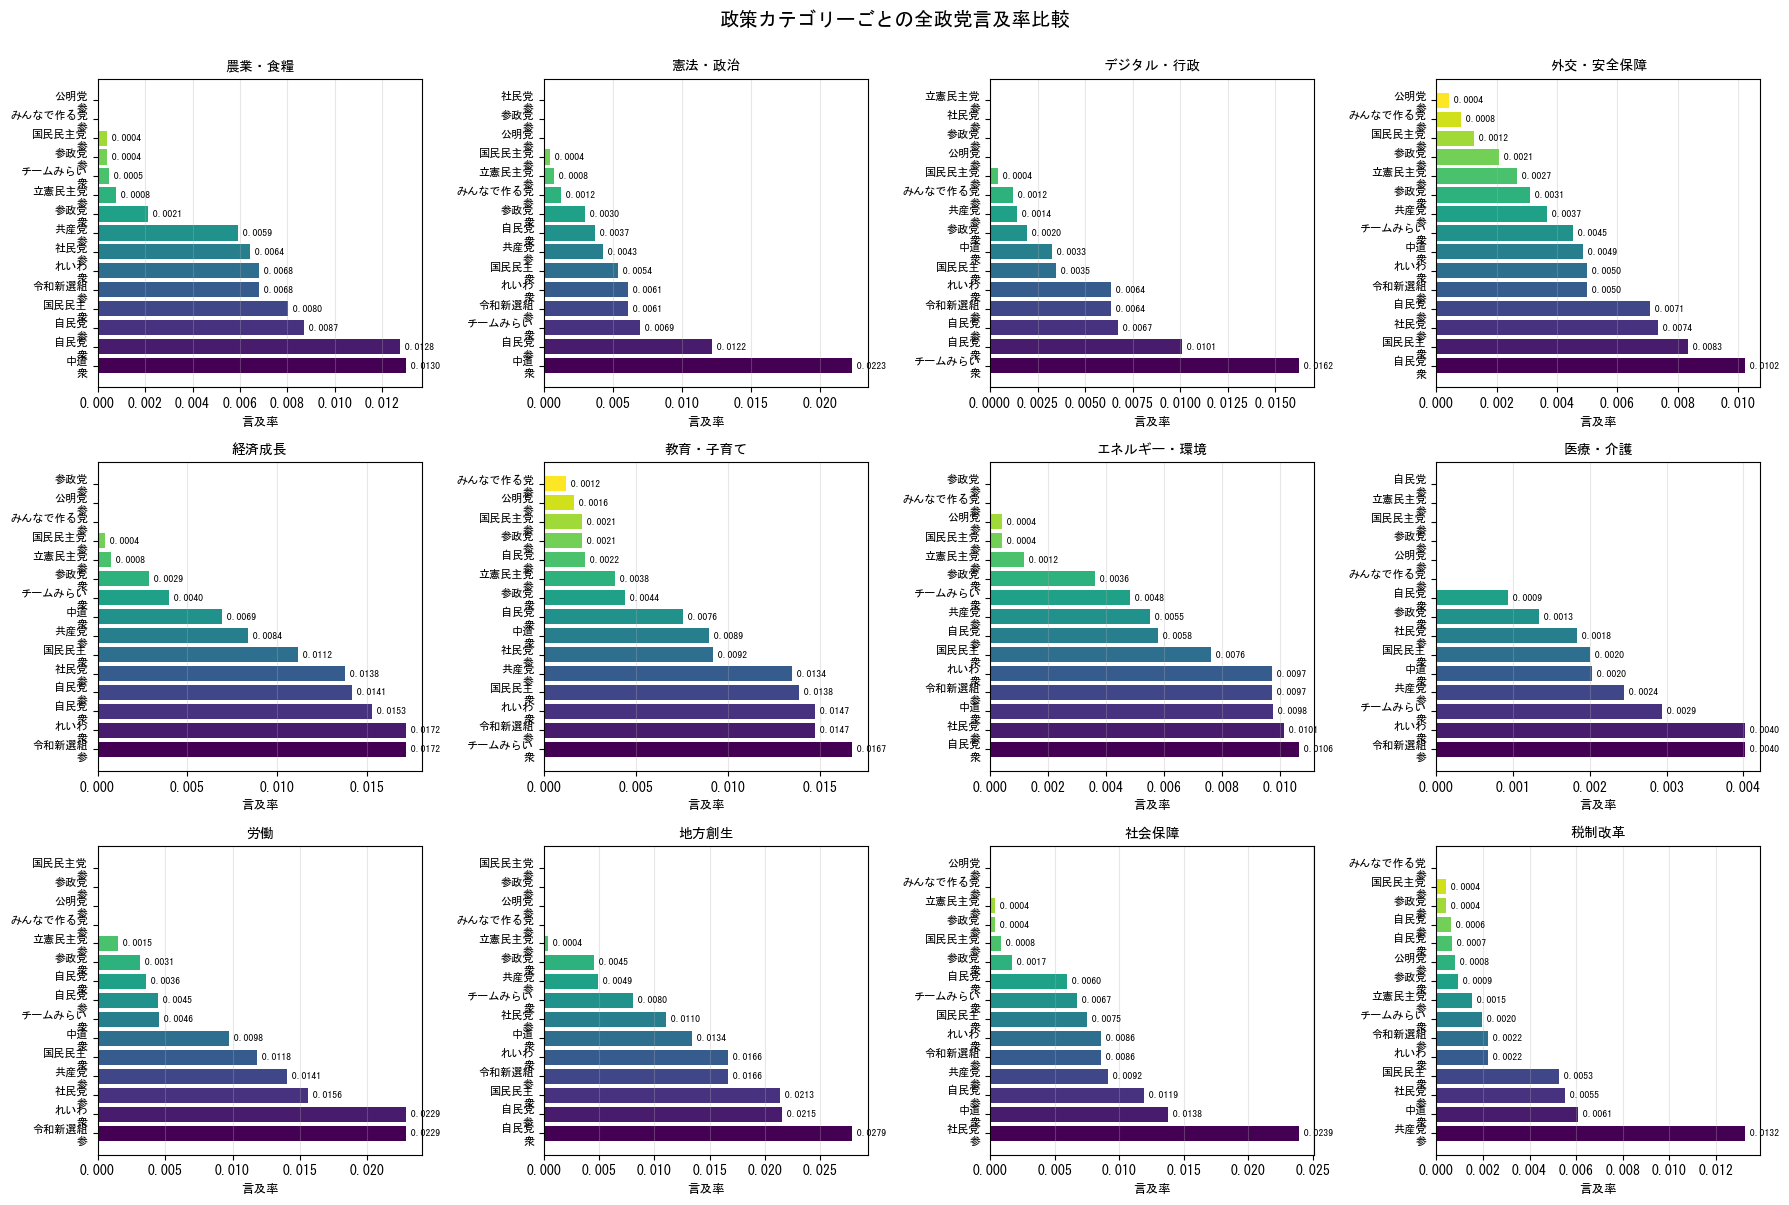

In [93]:
# 案1: 複合棒グラフ（政策カテゴリーごとのサブプロット）
# 12個の政策カテゴリーそれぞれについて、全政党の言及率を棒グラフで比較
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

policy_categories = df.columns.tolist()

for idx, policy in enumerate(policy_categories):
    ax = axes[idx]
    
    # 政策ごとの言及率を降順でソート
    data_sorted = df[policy].sort_values(ascending=False)
    
    # 棒グラフを描画
    colors = plt.cm.viridis(np.linspace(0, 1, len(data_sorted)))
    ax.barh(range(len(data_sorted)), data_sorted.values, color=colors)
    
    ax.set_yticks(range(len(data_sorted)))
    ax.set_yticklabels([name.replace('_', '\n') for name in data_sorted.index], fontsize=8)
    ax.set_xlabel('言及率', fontsize=9)
    ax.set_title(policy, fontsize=10, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    
    # 値を棒の上に表示
    for i, v in enumerate(data_sorted.values):
        if v > 0:
            ax.text(v, i, f' {v:.4f}', va='center', fontsize=7)

plt.suptitle('政策カテゴリーごとの全政党言及率比較', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

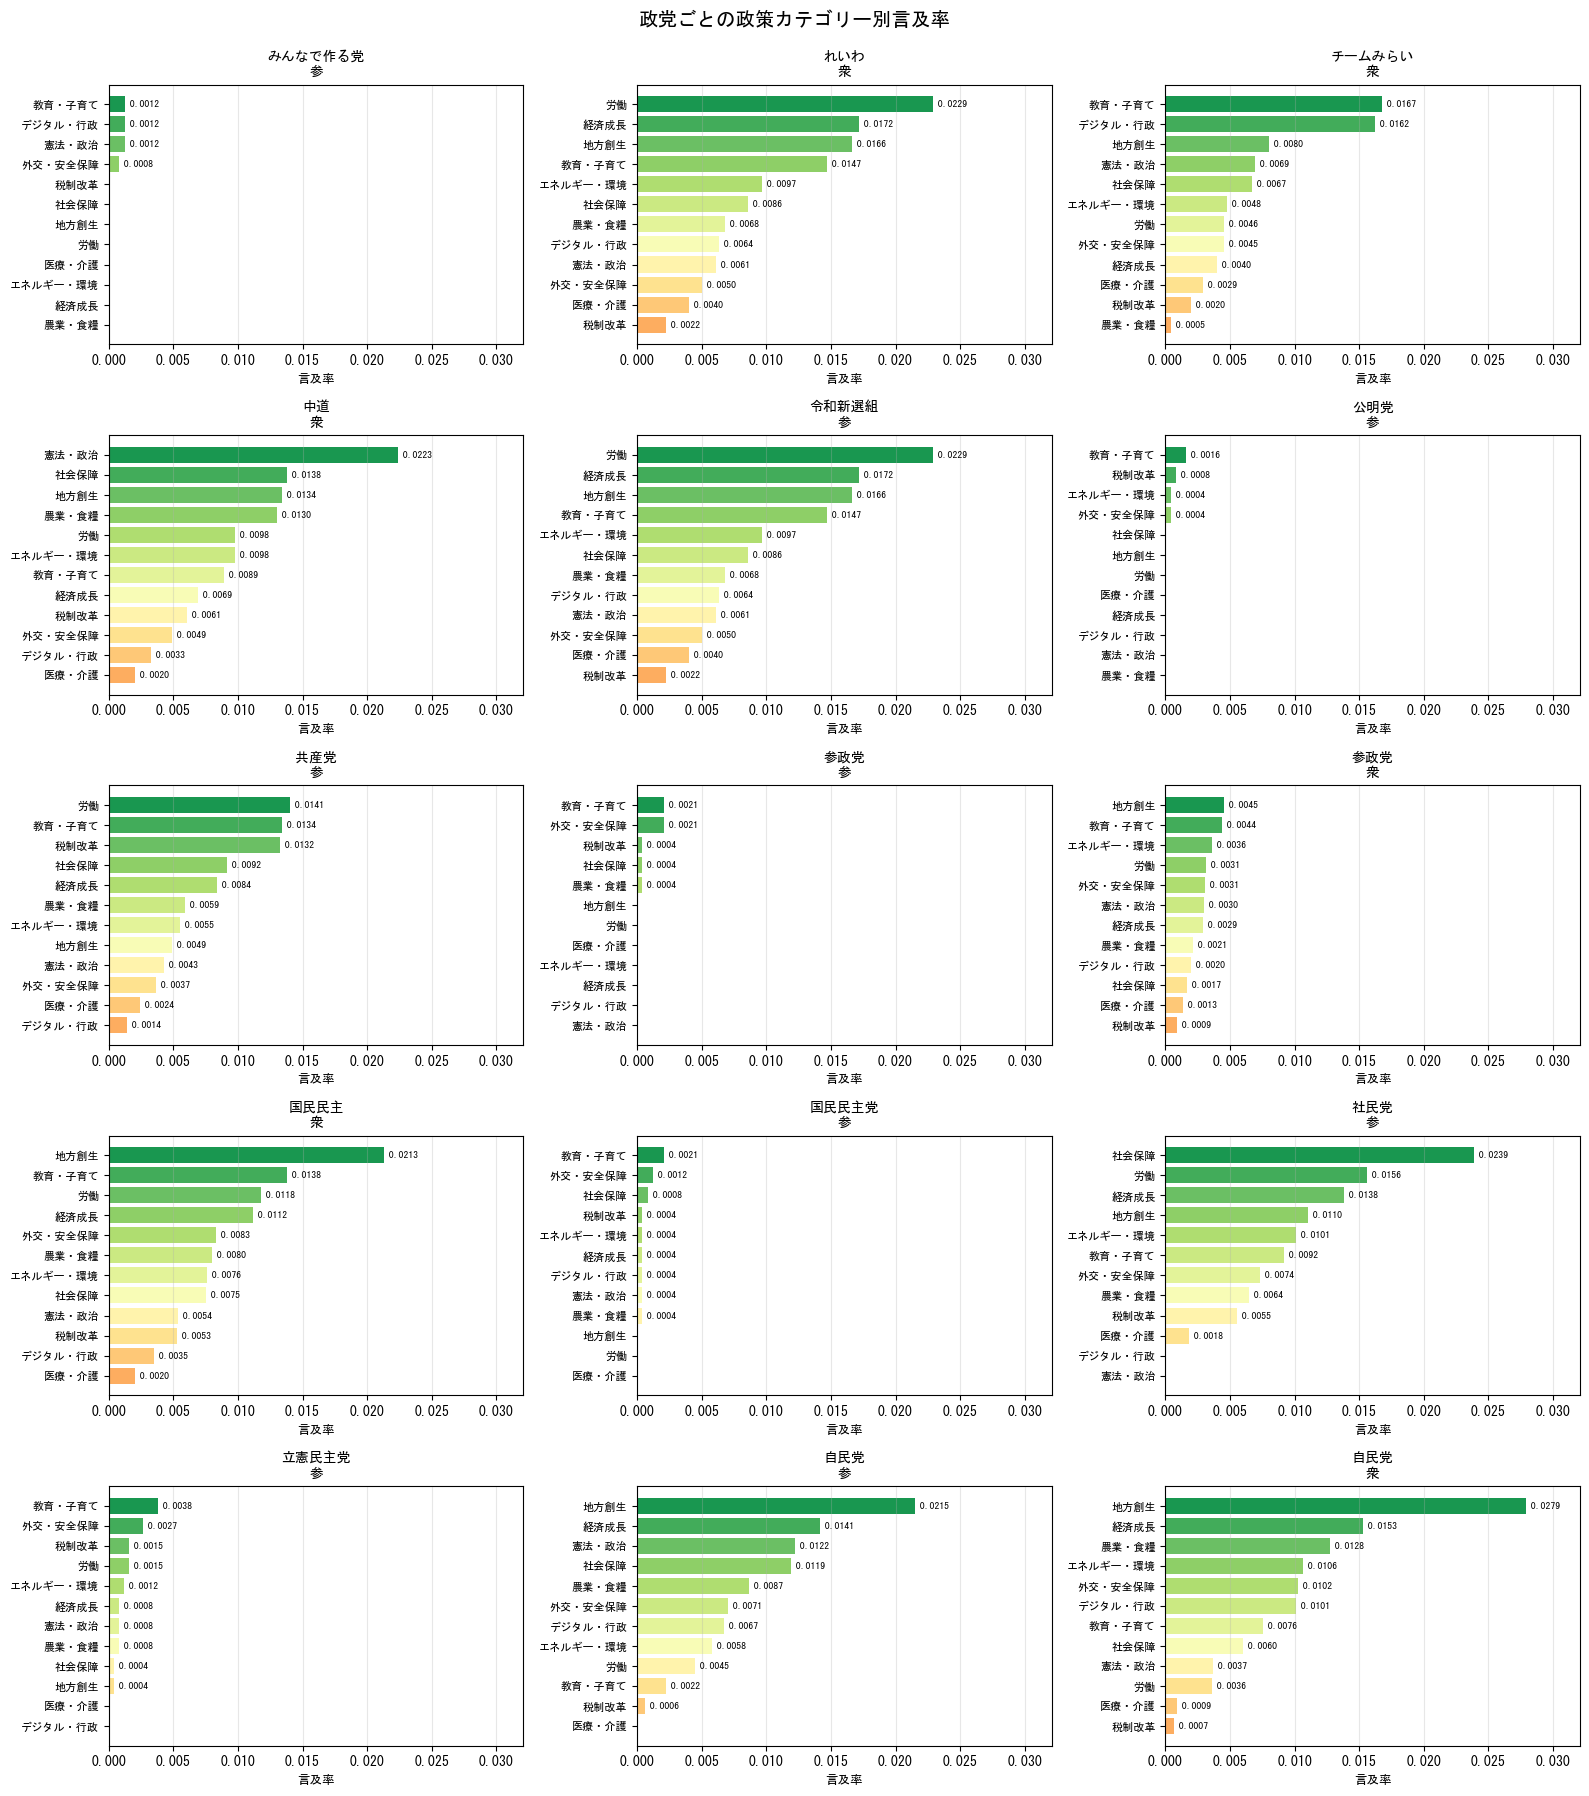

In [94]:
# 案3: 政党ごとの横棒グラフ（どの政策に言及が集中しているか）
# 各政党について、政策カテゴリーごとの言及率を表示
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()

for idx, party in enumerate(df.index):
    ax = axes[idx]
    
    # 政党ごとの言及率を降順でソート
    party_data = df.loc[party].sort_values(ascending=True)
    
    # 横棒グラフを描画
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(party_data)))
    ax.barh(range(len(party_data)), party_data.values, color=colors)
    
    ax.set_yticks(range(len(party_data)))
    ax.set_yticklabels(party_data.index, fontsize=8)
    ax.set_xlabel('言及率', fontsize=9)
    ax.set_title(party.replace('_', '\n'), fontsize=10, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlim(0, df.max().max() * 1.15)
    
    # 値を棒の上に表示
    for i, v in enumerate(party_data.values):
        if v > 0:
            ax.text(v, i, f' {v:.4f}', va='center', fontsize=7)

# 不要なサブプロットを非表示
for idx in range(len(df), len(axes)):
    axes[idx].axis('off')

plt.suptitle('政党ごとの政策カテゴリー別言及率', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

C:\Users\sk062\AppData\Local\Temp\ipykernel_18208\4251519905.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax1.boxplot([df.loc[party].values for party in df.index],
C:\Users\sk062\AppData\Local\Temp\ipykernel_18208\4251519905.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = ax2.boxplot([df[policy].values for policy in df.columns],


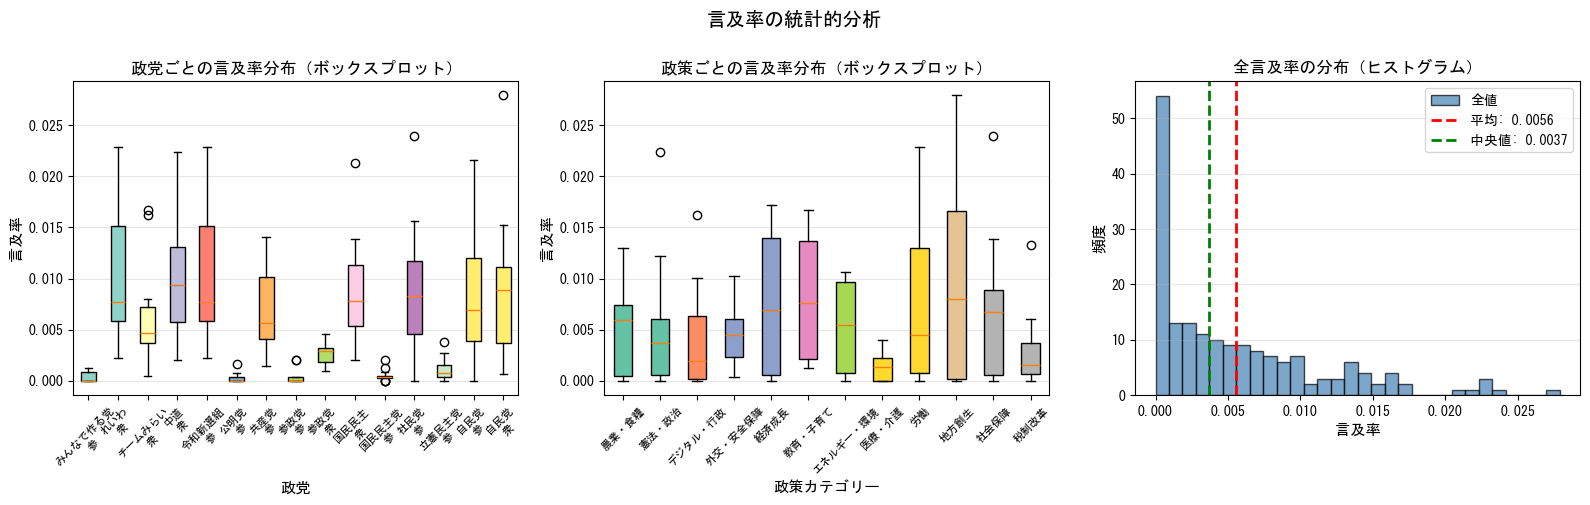

言及率の統計情報

全体統計:
  最小値: 0.000000
  最大値: 0.027896
  平均値: 0.005557
  中央値: 0.003693
  標準偏差: 0.005978
  ゼロでない値の割合: 82.8%

政党ごとの統計:
                 平均        最大        最小  ゼロ以外
政党                                           
みんなで作る党_参  0.000373  0.001222  0.000000     4
れいわ_衆      0.010010  0.022860  0.002217    12
チームみらい_衆   0.006488  0.016736  0.000466    12
中道_衆       0.009515  0.022349  0.002032    12
令和新選組_参    0.010013  0.022866  0.002217    12
公明党_参      0.000272  0.001633  0.000000     4
共産党_参      0.007198  0.014056  0.001426    12
参政党_参      0.000449  0.002074  0.000000     5
参政党_衆      0.002726  0.004540  0.000929    12
国民民主_衆     0.008813  0.021319  0.002005    12
国民民主党_参    0.000552  0.002068  0.000000     9
社民党_参      0.008732  0.023897  0.000000    10
立憲民主党_参    0.001152  0.003840  0.000000    10
自民党_参      0.007956  0.021536  0.000000    11
自民党_衆      0.009110  0.027896  0.000664    12

政策ごとの統計:
                平均        最大        最小  ゼロ以外
農業・食糧     0.004837  0.013003  0.00000

In [95]:
# 案4: ボックスプロット + ヒストグラム（分布の統計的可視化）
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. 政党ごとの言及率分布（ボックスプロット）
ax1 = axes[0]
df_for_box = df.T  # 転置して政党をカテゴリーにする
bp = ax1.boxplot([df.loc[party].values for party in df.index], 
                   labels=[name.replace('_', '\n') for name in df.index],
                   patch_artist=True)

# ボックスに色を付ける
colors = plt.cm.Set3(np.linspace(0, 1, len(df)))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax1.set_ylabel('言及率', fontsize=11)
ax1.set_xlabel('政党', fontsize=11)
ax1.set_title('政党ごとの言及率分布（ボックスプロット）', fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=45, labelsize=8)
ax1.grid(axis='y', alpha=0.3)

# 2. 政策ごとの言及率分布（ボックスプロット）
ax2 = axes[1]
bp2 = ax2.boxplot([df[policy].values for policy in df.columns],
                    labels=df.columns,
                    patch_artist=True)

colors2 = plt.cm.Set2(np.linspace(0, 1, len(df.columns)))
for patch, color in zip(bp2['boxes'], colors2):
    patch.set_facecolor(color)

ax2.set_ylabel('言及率', fontsize=11)
ax2.set_xlabel('政策カテゴリー', fontsize=11)
ax2.set_title('政策ごとの言及率分布（ボックスプロット）', fontsize=12, fontweight='bold')
ax2.tick_params(axis='x', rotation=45, labelsize=8)
ax2.grid(axis='y', alpha=0.3)

# 3. 全体の言及率分布（ヒストグラム）
ax3 = axes[2]
all_values = df.values.flatten()
all_values_nonzero = all_values[all_values > 0]

ax3.hist(all_values, bins=30, color='steelblue', alpha=0.7, edgecolor='black', label='全値')
ax3.axvline(all_values.mean(), color='red', linestyle='--', linewidth=2, label=f'平均: {all_values.mean():.4f}')
ax3.axvline(np.median(all_values), color='green', linestyle='--', linewidth=2, label=f'中央値: {np.median(all_values):.4f}')

ax3.set_xlabel('言及率', fontsize=11)
ax3.set_ylabel('頻度', fontsize=11)
ax3.set_title('全言及率の分布（ヒストグラム）', fontsize=12, fontweight='bold')
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)

plt.suptitle('言及率の統計的分析', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# 統計情報の表示
print("=" * 80)
print("言及率の統計情報")
print("=" * 80)
print(f"\n全体統計:")
print(f"  最小値: {all_values.min():.6f}")
print(f"  最大値: {all_values.max():.6f}")
print(f"  平均値: {all_values.mean():.6f}")
print(f"  中央値: {np.median(all_values):.6f}")
print(f"  標準偏差: {np.std(all_values):.6f}")
print(f"  ゼロでない値の割合: {len(all_values_nonzero) / len(all_values) * 100:.1f}%")

print(f"\n政党ごとの統計:")
party_stats = pd.DataFrame({
    '平均': df.mean(axis=1),
    '最大': df.max(axis=1),
    '最小': df.min(axis=1),
    'ゼロ以外': (df != 0).sum(axis=1)
})
print(party_stats.to_string())

print(f"\n政策ごとの統計:")
policy_stats = pd.DataFrame({
    '平均': df.mean(axis=0),
    '最大': df.max(axis=0),
    '最小': df.min(axis=0),
    'ゼロ以外': (df != 0).sum(axis=0)
})
print(policy_stats.to_string())